In [1]:
import mina
import scanpy as sc
import scanpy.external as sce
import numpy as np
import decoupler as dc
import math
import mofaflex as mf
import mudata as md
import pandas as pd
import matplotlib.pyplot as plt
import squidpy as sq

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Versio

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



## Notes on the experimental design

This dataset contains 5 time points with at least 4 slides - These however come from either the same mouse (technical replicates). For this analysis, we will focus on the SlideID

## Time course (original)

In [3]:
adata_tc = sc.read_h5ad("/nfs/research/saezrodriguez/data/ERC_CartoHostBug/MERFISH/adata.h5ad")
adata_tc.obs[["Tier1", "Tier2"]].drop_duplicates().to_csv("./src_data/Tier1_Tier2.csv", index=False)
mina_tier = pd.read_csv("./src_data/Tier1_5_mapping.csv")

#Left join the two dataframes by the "Tier1" and "Tier2" column
adata_tc.obs = pd.merge(adata_tc.obs,
                     mina_tier, 
                     how = 'left', left_on= ['Tier1','Tier2'], right_on=['Tier1','Tier2'])

adata_tc.obs = adata_tc.obs[['x','y','Mouse_ID', 'Technical_repeat_number', 'Sample_type',
                        'Slice_ID', 'FOV', 'Cell_ID', 'Tier1','TierMINA']]

adata_tc.obsm["spatial"] = np.asarray(adata_tc.obs[["x","y"]].copy(), dtype=np.float64)

adata_tc.X = adata_tc.raw.X.copy()

/hps/software/spack/opt/spack/linux-rhel9-cascadelake/gcc-14.2.0/python-3.13.2-ccnbj22zvwiaansq6dz2tukzrqw3kqnz/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
/hps/software/spack/opt/spack/linux-rhel9-cascadelake/gcc-14.2.0/python-3.13.2-ccnbj22zvwiaansq6dz2tukzrqw3kqnz/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.


In [4]:
adata_35 =  sc.read_h5ad("/nfs/research/saezrodriguez/data/ERC_CartoHostBug/MERFISH/adata_day35.h5ad")
mina_tier = pd.read_csv("./src_data/Tier1_Tier3_Tier1.5_mapping.csv")
#Left join the two dataframes by the "Tier1" and "Tier2" column
adata_35.obs = pd.merge(adata_35.obs,
                     mina_tier, 
                     how = 'left', left_on= ['Tier1','Tier3'], right_on=['Tier1','Tier3'])

adata_35.obs["Cell_ID"] = adata_35.obs["cell_IDs"]

adata_35.obs = adata_35.obs[['x','y','Mouse_ID', 'Technical_repeat_number', 'Sample_type',
                        'Slice_ID', 'FOV', 'Cell_ID', 'Tier1','TierMINA']]

adata_35.obsm["spatial"] = np.asarray(adata_35.obs[["x","y"]].copy(), dtype=np.float64)

adata_35.X = adata_35.raw.X.copy()

/hps/software/spack/opt/spack/linux-rhel9-cascadelake/gcc-14.2.0/python-3.13.2-ccnbj22zvwiaansq6dz2tukzrqw3kqnz/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
/hps/software/spack/opt/spack/linux-rhel9-cascadelake/gcc-14.2.0/python-3.13.2-ccnbj22zvwiaansq6dz2tukzrqw3kqnz/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.


In [7]:
import anndata as ad

adata = ad.concat({"first":adata_tc, "second":adata_35}, label="dataset")

/nfs/research/saezrodriguez/rico/MINA_mscript/.venv/lib/python3.13/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
/nfs/research/saezrodriguez/rico/MINA_mscript/.venv/lib/python3.13/site-packages/anndata/_core/anndata.py:1882: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


/nfs/research/saezrodriguez/rico/MINA_mscript/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
/nfs/research/saezrodriguez/rico/MINA_mscript/.venv/lib/python3.13/site-packages/squidpy/pl/_spatial_utils.py:982: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored


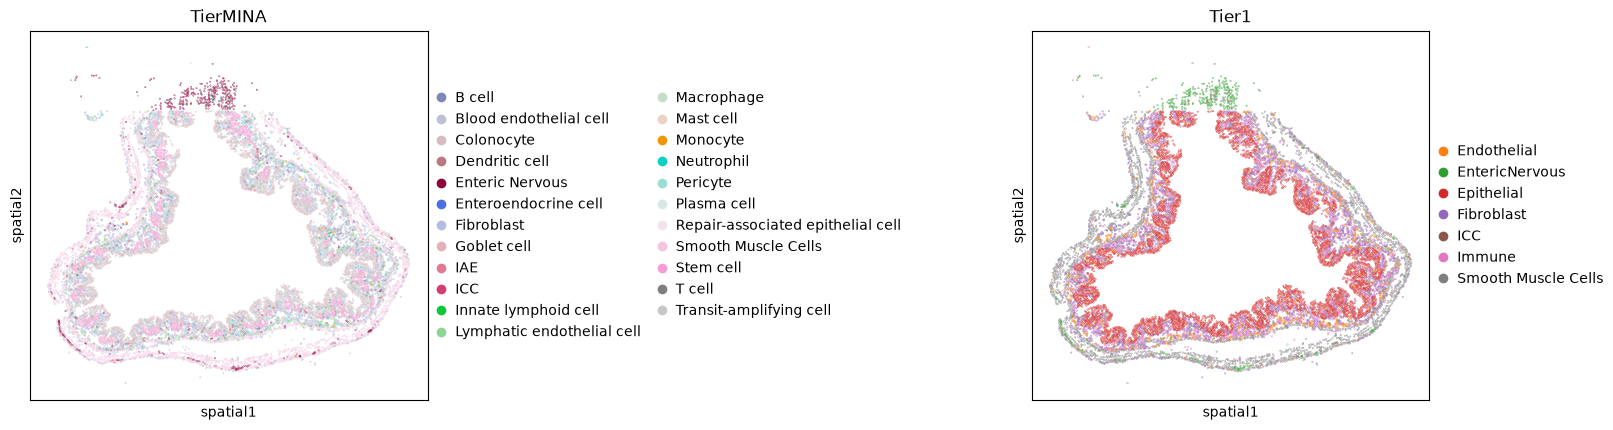

In [8]:
sq.pl.spatial_scatter(
    adata,
    library_key= "Slice_ID",
    library_id = "072523_D35_m11_1_slice_1",
    shape=None,
    color=[
        "TierMINA","Tier1"
    ],
    wspace=0.6,
)

In [9]:
adata.write_h5ad("/nfs/research/saezrodriguez/data/ERC_CartoHostBug/MERFISH/full_adata.h5ad")